# Racing with RL

Train a policy that drives a car around Laguna Seca to achieve the fastest lap time!

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from racer_rl import (
    Step,
    Track,
    format_time,
    make_env,
    rollout,
    show_video,
    time_trial,
)

TRACK = "laguna_seca"
DYNAMICS = "dynamic" # "kinematic" 

## 1. Environment

`make_env` will return the `gym.Env` type environment object, which is the standard Gymnasium api

here action is a Box, meaning it is continuous control

observation: (19,) action: Box(-1.0, 1.0, (2,), float32)


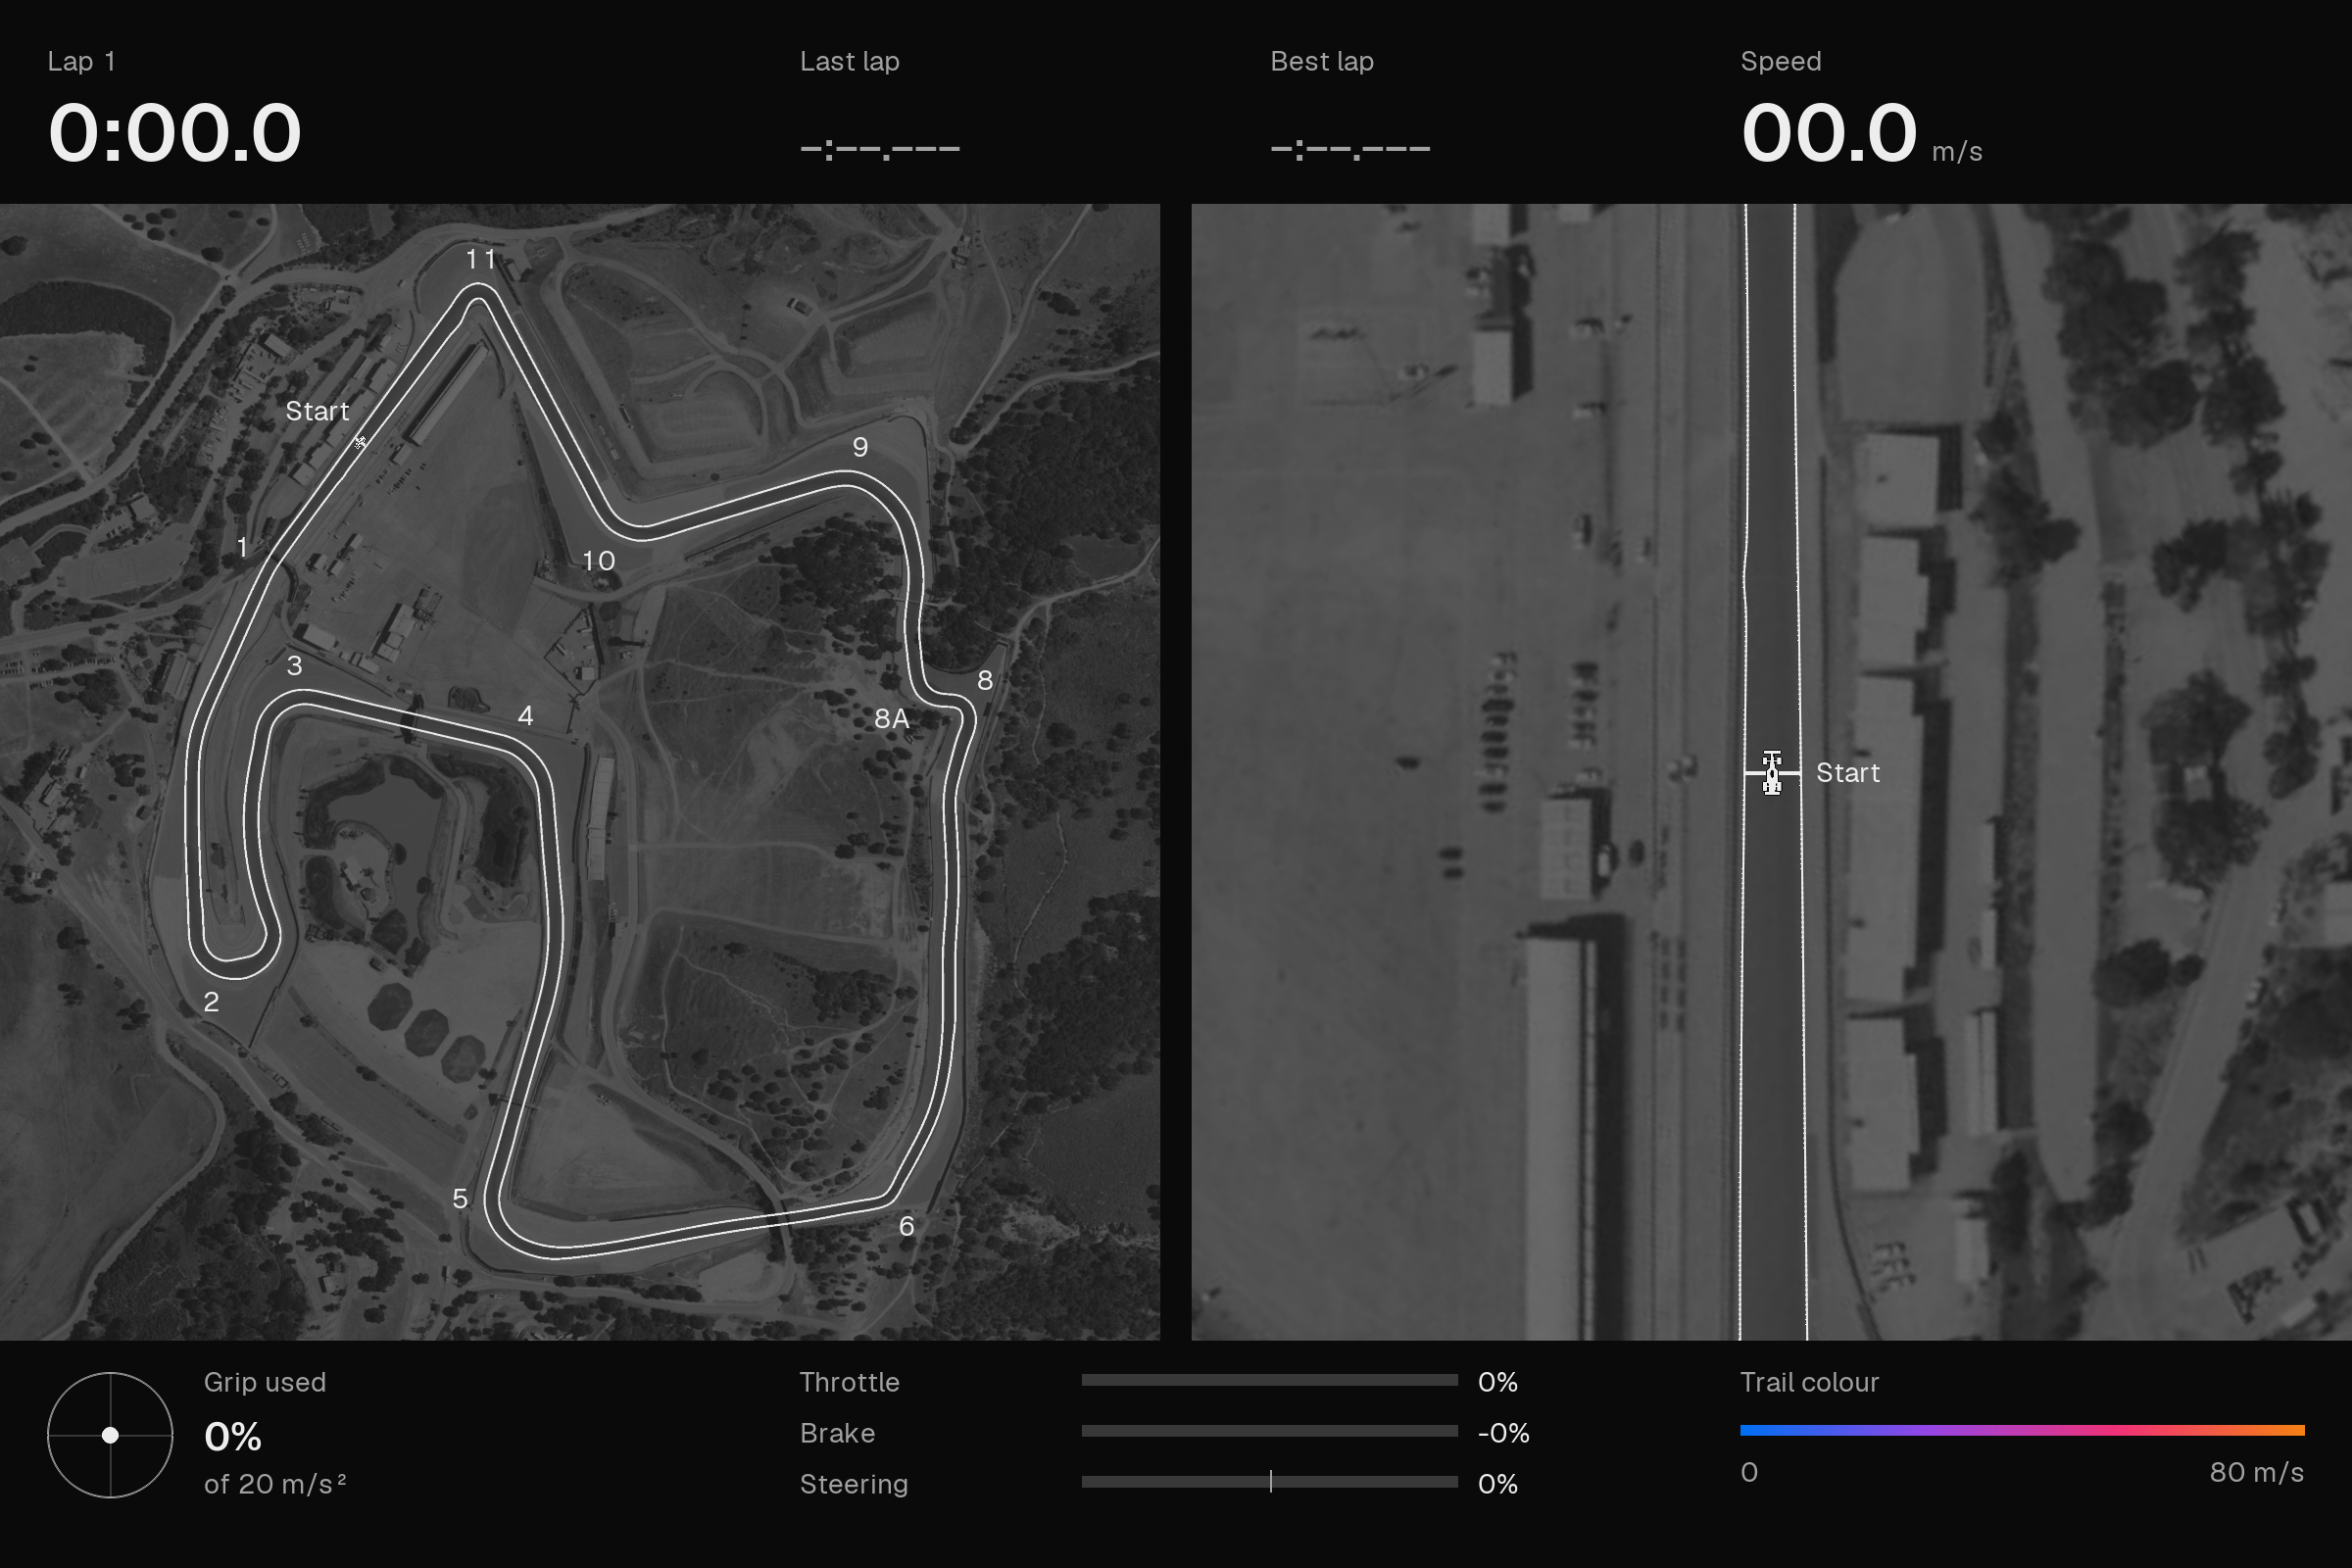

In [2]:
env = make_env(TRACK, render_mode="rgb_array", random_start=False, dynamics=DYNAMICS)
obs, info = env.reset()
print("observation:", env.observation_space.shape, "action:", env.action_space)
Image.fromarray(env.render())

**Observation**, 19 dim:

| index | content |
| --- | --- |
| 0 | speed / top speed |
| 1 | offset from the centerline / half the track width (±1 at the edges) |
| 2, 3 | sin and cos of the heading relative to the track |
| 4 | where the front wheels are / full lock (±1) |
| 5 | sideslip [rad] |
| 6 | yaw rate [rad/s] |
| 7 to 18 | curvature of the track 0, 10, 20, 30, 45, 60, 80, 100, 130, 160, 200 and 250 m ahead, times 50 m |

**Action**, 2 dim, each in [-1, 1], applied at 10 Hz:

| index | content |
| --- | --- |
| 0 | pedal: throttle if positive, brake if negative |
| 1 | steering: right if positive |

**Episode.** Ends when the centre of the car leaves the track or timeout

## Play with the environment

Let's see how the car goes when we just blindly do some constant action:

In [3]:
def full_throttle_policy(obs: np.ndarray) -> np.ndarray:
    # ignore the obs
    return np.array([0.5, -0.008])  # [pedal, steering]

result = time_trial(full_throttle_policy, TRACK,laps=2, video="videos/full_throttle", dynamics=DYNAMICS)
print(result)
show_video(result.video)

went off track after 0.04 laps


## 2. reward function

A reward function takes a `Step`, which describes what happened during one step of the environment, and returns a number.

| field | meaning |
| --- | --- |
| `progress` | distance covered [m]|
| `speed` | speed  [m/s] |
| `lateral` | offset from the centerline [m], positive to the right |
| `heading_error` | heading relative to the direction of the track [rad], positive to the right |
| `on_track` | bool |
| `pedal`, `steering` | [-1, 1] |
| `steering_actual` |  [-1, 1]; it lags behind `steering` due to max steering rate |
| `previous_pedal`, `previous_steering` | the action of the previous step |
| `longitudinal_acceleration` | [m/s²] |
| `lateral_acceleration` | [m/s²], positive to the right |
| `sideslip` | angle between where the car points and where it is going [rad]; large when the car slides |
| `yaw_rate` | [rad/s], positive to the right |
| `curvature` | curvature of the track at the car [1/m], positive in right-hand corners |
| `lap_time` | time of the lap completed during this step [s], otherwise `None` |
| `time` | time since the start of the episode [s] |
| `dt` | duration of a step [s] |
| `max_speed`, `grip` | top speed [m/s] and tyre grip [m/s²] of the car |
| `half_width` | half the track width where the car is [m]: the car is on track while `abs(lateral) <= half_width` |


In [4]:
# the thing we ultimately want is fast lap time. but how to design a "proper" reward function? 

def reward(step: Step) -> float:
    'TODO'
    reward = step.progress                                   # the objective, dense
    # reward -= 0.1 * (step.steering - step.previous_steering) ** 2 
    if not step.on_track:
        reward -= 10.0  
     

    return reward

### Check your reward function

Here we can do some sanity checks with some dummy policies

In [5]:
drivers = {
    "step on gas": lambda obs: np.array([1.0, 0.0]),
    "not moving": lambda obs: np.array([0.0, 0.0]),
}

for name, driver in drivers.items():
    r = rollout(driver, reward, TRACK, dynamics=DYNAMICS)
    ending = "off track" if r["off_track"] else "driving"
    print(
        f"{name:22s} return {r['return']:8.1f}   "
        f"{r['distance']:5.0f} m in {r['time']:4.1f} s, {ending}"
    )

step on gas            return    163.3     173 m in  5.9 s, off track
not moving             return      0.0       0 m in 60.0 s, driving


## 3. Your Racing Agent

Good implementations of various RL algorithms can be found in [Stable-Baselines3](https://stable-baselines3.readthedocs.io/).
You should read the differences between those algorithms. 

In [6]:
from stable_baselines3 import PPO, A2C, DDPG, SAC, TD3
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import SubprocVecEnv

RUN = Path("runs/your_policy")  

train_env = make_vec_env(
    make_env,
    n_envs=32,
    seed=42,
    env_kwargs={"track": TRACK, "reward": reward, "dynamics": DYNAMICS},
    vec_env_cls=SubprocVecEnv,
    monitor_dir=str(RUN / "monitor"),  # each environment logs its episodes there
)



In [9]:
# TODO train your policy here
model = PPO(
    "MlpPolicy",
    train_env,
    n_steps=1024,
    batch_size=2048,
    n_epochs=10,
    gamma=0.99,
    learning_rate=3e-4,
    policy_kwargs=dict(log_std_init=-1.0),
    device="cpu",
    verbose=1,
    tensorboard_log=str(RUN / "tb"),
)

model.learn(total_timesteps=5000000)
model.save(RUN / "model")
train_env.close()

Using cpu device


BrokenPipeError: [Errno 32] Broken pipe


Define `policy`: a function that takes an observation and returns an action.

In [ ]:
# TODO set your trained policy here
your_policy = model

def policy(obs: np.ndarray) -> np.ndarray:
    return your_policy.predict(obs, deterministic=True)[0]

## 4. Test your policy by racing it

Here we will perform a single car run in the time trial format of 3 laps. (is your policy stable enough to finish at least 3 laps?)

The whole time trial is saved, submit this `.npz` file to the Google Drive linked in the assignment `.pdf` or Piazza

In [ ]:
# note 1st lap starts from 0 speed so it will likely be slower than other laps
result = time_trial(policy, TRACK, video="videos/your_policy", dynamics=DYNAMICS,laps=3, save_trial="laps/your_name_or_nickname")
print(result)
show_video(result.video)